Let's keep going. Let's refine the interpolation method rather than just using `griddata(method='cubic')` . We are now going to use a method called the "Inverse Distance Weighting", which is a spatial interpolation method that estimates missing values by weighing the distance of nearby measurment points. 



In [1]:
# Imports
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.interpolate import griddata
import matplotlib.cm as cm
import matplotlib.colors as colors
import imageio
import glob
import skgstat as skg
from scipy.spatial.distance import cdist

In [2]:
# --- Load Water Mass Codes ---
# Load the manual and correctly rename the columns
manual_filepath = '../sources/水環境総合情報サイト/water_manual.xls'
codes_df = pd.read_excel(manual_filepath, sheet_name='3. Water mass code', header=3)
codes_df = codes_df.rename(columns={
    'Water Mass Code': 'watercode',
    'Water Mass Name': 'watermass_name',
    'Water Mass Division': 'division',
    'Water Mass Details': 'details'
}) #[cite: 41, 44-49]

# --- Load and Combine Yearly Environmental Data ---
base_data_path = '../data/raw/environmental_data' #[cite: 159]
gdfs = []
for dirpath, _, filenames in os.walk(base_data_path):
    if 'output.shp' in filenames: #[cite: 164, 165]
        # Extract year from the folder name
        try:
            year = int(os.path.basename(dirpath).split('_')[0]) #[cite: 168]
        except (ValueError, IndexError):
            continue
        
        # Read shapefile, add year, and append to list
        shp_filepath = os.path.join(dirpath, 'output.shp') #[cite: 171]
        gdf_temp = gpd.read_file(shp_filepath) #[cite: 172]
        gdf_temp['year'] = year #[cite: 173]
        gdfs.append(gdf_temp) #[cite: 174]

# Concatenate all yearly data into one GeoDataFrame
all_points_gdf = pd.concat(gdfs, ignore_index=True) #[cite: 177]
print(f"Loaded and combined {len(all_points_gdf)} data points from {len(gdfs)} files.")

Loaded and combined 41346 data points from 84 files.


In [7]:
# --- Merge Datasets ---
# Ensure 'watercode' columns are the same integer type before merging
all_points_gdf['watercode'] = all_points_gdf['watercode'].astype(int) #[cite: 270]
codes_df['watercode'] = codes_df['watercode'].astype(int) #[cite: 270]
merged_gdf = all_points_gdf.merge(codes_df, on='watercode', how='left') #[cite: 277]

# --- Create Season Column ---
def get_season(month): #[cite: 548]
    """Takes a month (1-12) and returns the corresponding season.""" #[cite: 549]
    if month in [12, 1, 2]: return 'Winter' #[cite: 550]
    elif month in [3, 4, 5]: return 'Spring' #[cite: 551]
    elif month in [6, 7, 8, 9]: return 'Summer' #[cite: 552]
    elif month in [10, 11]: return 'Autumn' #[cite: 553]
    else: return 'Unknown' #[cite: 556]

merged_gdf['season'] = merged_gdf['surveymont'].apply(get_season) #[cite: 557]

# --- Final Cleanup ---
# Ensure 'temp' column is a numeric type for calculations
merged_gdf['temp'] = pd.to_numeric(merged_gdf['temp'], errors='coerce') #[cite: 688]

print("Data merged and 'season' column created successfully.")
print(f"Merged dataset contains {len(merged_gdf)} records.")
print(merged_gdf[['year', 'surveymont', 'season', 'division']].head()) #[cite: 561]

Data merged and 'season' column created successfully.
Merged dataset contains 41346 records.
   year  surveymont  season   division
0  1981           5  Spring  Osaka Bay
1  1981           8  Summer  Osaka Bay
2  1981           1  Winter  Osaka Bay
3  1981           5  Spring  Osaka Bay
4  1981           8  Summer  Osaka Bay


In [13]:
# Filter for surface temperature (SST) and bottom temperature (SBT) data
analysis_df = merged_gdf[
    (merged_gdf['saisuipoin'].isin([1, 2]))
].dropna(subset=['temp']).copy()

SST = analysis_df.loc[analysis_df['saisuipoin'] == 1]
SBT = analysis_df.loc[analysis_df['saisuipoin'] == 2]

print(f"Prepared {len(analysis_df)} data points for analysis.")
print(f"SST points: {len(SST)}, SBT points: {len(SBT)}")

vmin = analysis_df['temp'].min()
vmax = analysis_df['temp'].max()
print(f"Temperature range: {vmin} to {vmax}")

# Check for any remaining NaNs in 'temp' or geometry
if analysis_df['temp'].isnull().any():
    print("Warning: Still NaN values in 'temp' after initial dropna.")
if analysis_df['geometry'].isnull().any():
    print("Warning: Still NaN values in 'geometry' after initial dropna.")

Prepared 35440 data points for analysis.
SST points: 20470, SBT points: 14970
Temperature range: 0.0 to 38.5


First, I need to calculate the decorelation scale for each of the sampling points. This is to determine how much each measurment points influence each other. To do this, first I need to determine the decorrelation distance, which is the distance where two points are considered not corrleated anymore. 


Calculated Decorrelation Length (D value) at 1/e: 0.2326 degrees


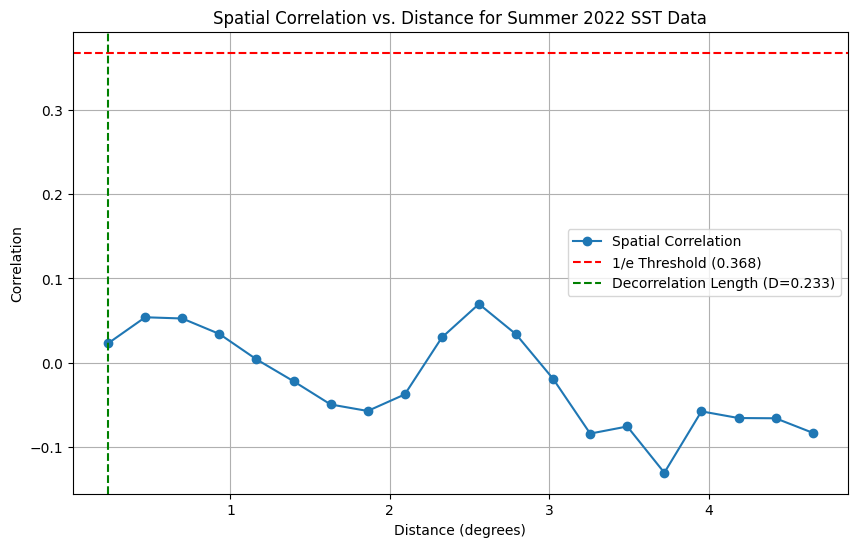

In [22]:
# --- Use data from a representative time period to find a characteristic k ---
# For example, let's use the summer data from a single, data-rich year (e.g., 2022)
data_for_k = SST[SST['year'] == 2022].copy()

# 1. Create the Variogram object
#    coords are the geometry points, values are the temperature measurements
V = skg.Variogram(
    coordinates=np.column_stack((data_for_k.geometry.x, data_for_k.geometry.y)),
    values=data_for_k['temp'].values,
    n_lags=20 # A common, robust model
)

# Extract the distance bins and the variance (dissimilarity) for each bin
distances = V.bins
variances = V.experimental

# --- 3. Convert Variance to Correlation ---
# We can approximate correlation: corr ≈ 1 - (normalized variance)
# The 'sill' of the variogram is the background variance of the data.
sill = np.var(data_for_k['temp'].values)
correlations = 1 - (variances / sill)

# --- 4. Find the Decorrelation Length (k) ---
# Find the first distance where the correlation drops below 1/e
threshold = 1 / (np.e) 
decorrelation_mask = correlations < threshold
if np.any(decorrelation_mask):
    D_parameter = distances[decorrelation_mask][0]
else:
    D_parameter = distances[-1]

print(f"\nCalculated Decorrelation Length (D value) at 1/e: {D_parameter:.4f} degrees")

# --- 5. Plot the Results for Verification ---
plt.figure(figsize=(10, 6))
plt.plot(distances, correlations, marker='o', linestyle='-', label='Spatial Correlation')
plt.axhline(y=threshold, color='r', linestyle='--', label=f'1/e Threshold ({threshold:.3f})')
plt.axvline(x=D_parameter, color='g', linestyle='--', label=f'Decorrelation Length (D={D_parameter:.3f})')
plt.xlabel('Distance (degrees)')
plt.ylabel('Correlation')
plt.title('Spatial Correlation vs. Distance for Summer 2022 SST Data')
plt.legend()
plt.grid(True)
plt.show()


Calculated Decorrelation Length (D value) at 1/e: 0.2326 degrees


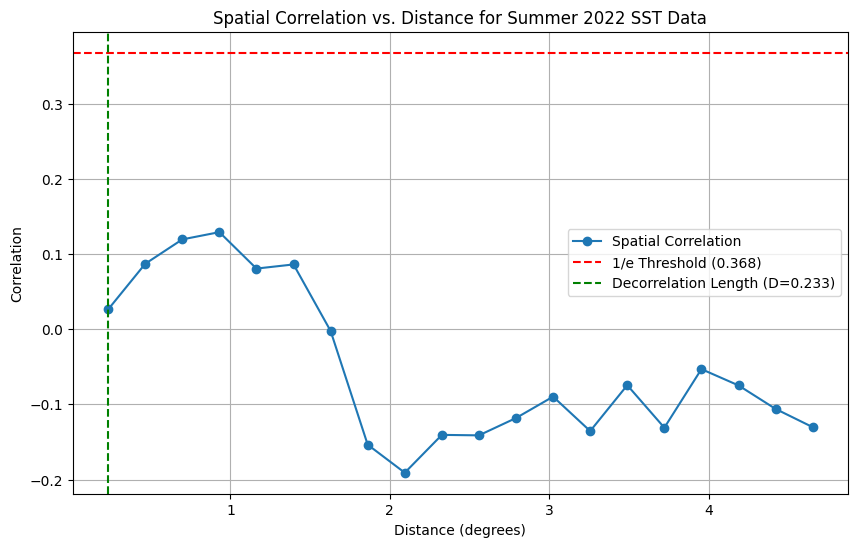

In [23]:
# Same thing for Bottom Temperature (SBT) data
data_for_k = SBT[SBT['year'] == 2022].copy()

# 1. Create the Variogram object
#    coords are the geometry points, values are the temperature measurements
V = skg.Variogram(
    coordinates=np.column_stack((data_for_k.geometry.x, data_for_k.geometry.y)),
    values=data_for_k['temp'].values,
    n_lags=20 # A common, robust model
)

# Extract the distance bins and the variance (dissimilarity) for each bin
distances = V.bins
variances = V.experimental

# --- 3. Convert Variance to Correlation ---
# We can approximate correlation: corr ≈ 1 - (normalized variance)
# The 'sill' of the variogram is the background variance of the data.
sill = np.var(data_for_k['temp'].values)
correlations = 1 - (variances / sill)

# --- 4. Find the Decorrelation Length (k) ---
# Find the first distance where the correlation drops below 1/e
threshold = 1 / (np.e) 
decorrelation_mask = correlations < threshold
if np.any(decorrelation_mask):
    D_parameter = distances[decorrelation_mask][0]
else:
    D_parameter = distances[-1]

print(f"\nCalculated Decorrelation Length (D value) at 1/e: {D_parameter:.4f} degrees")

# --- 5. Plot the Results for Verification ---
plt.figure(figsize=(10, 6))
plt.plot(distances, correlations, marker='o', linestyle='-', label='Spatial Correlation')
plt.axhline(y=threshold, color='r', linestyle='--', label=f'1/e Threshold ({threshold:.3f})')
plt.axvline(x=D_parameter, color='g', linestyle='--', label=f'Decorrelation Length (D={D_parameter:.3f})')
plt.xlabel('Distance (degrees)')
plt.ylabel('Correlation')
plt.title('Spatial Correlation vs. Distance for Summer 2022 SST Data')
plt.legend()
plt.grid(True)
plt.show()

Saved frame for 2022 to ../reports/figures/seasonal_gif_frames\frame_2022.png


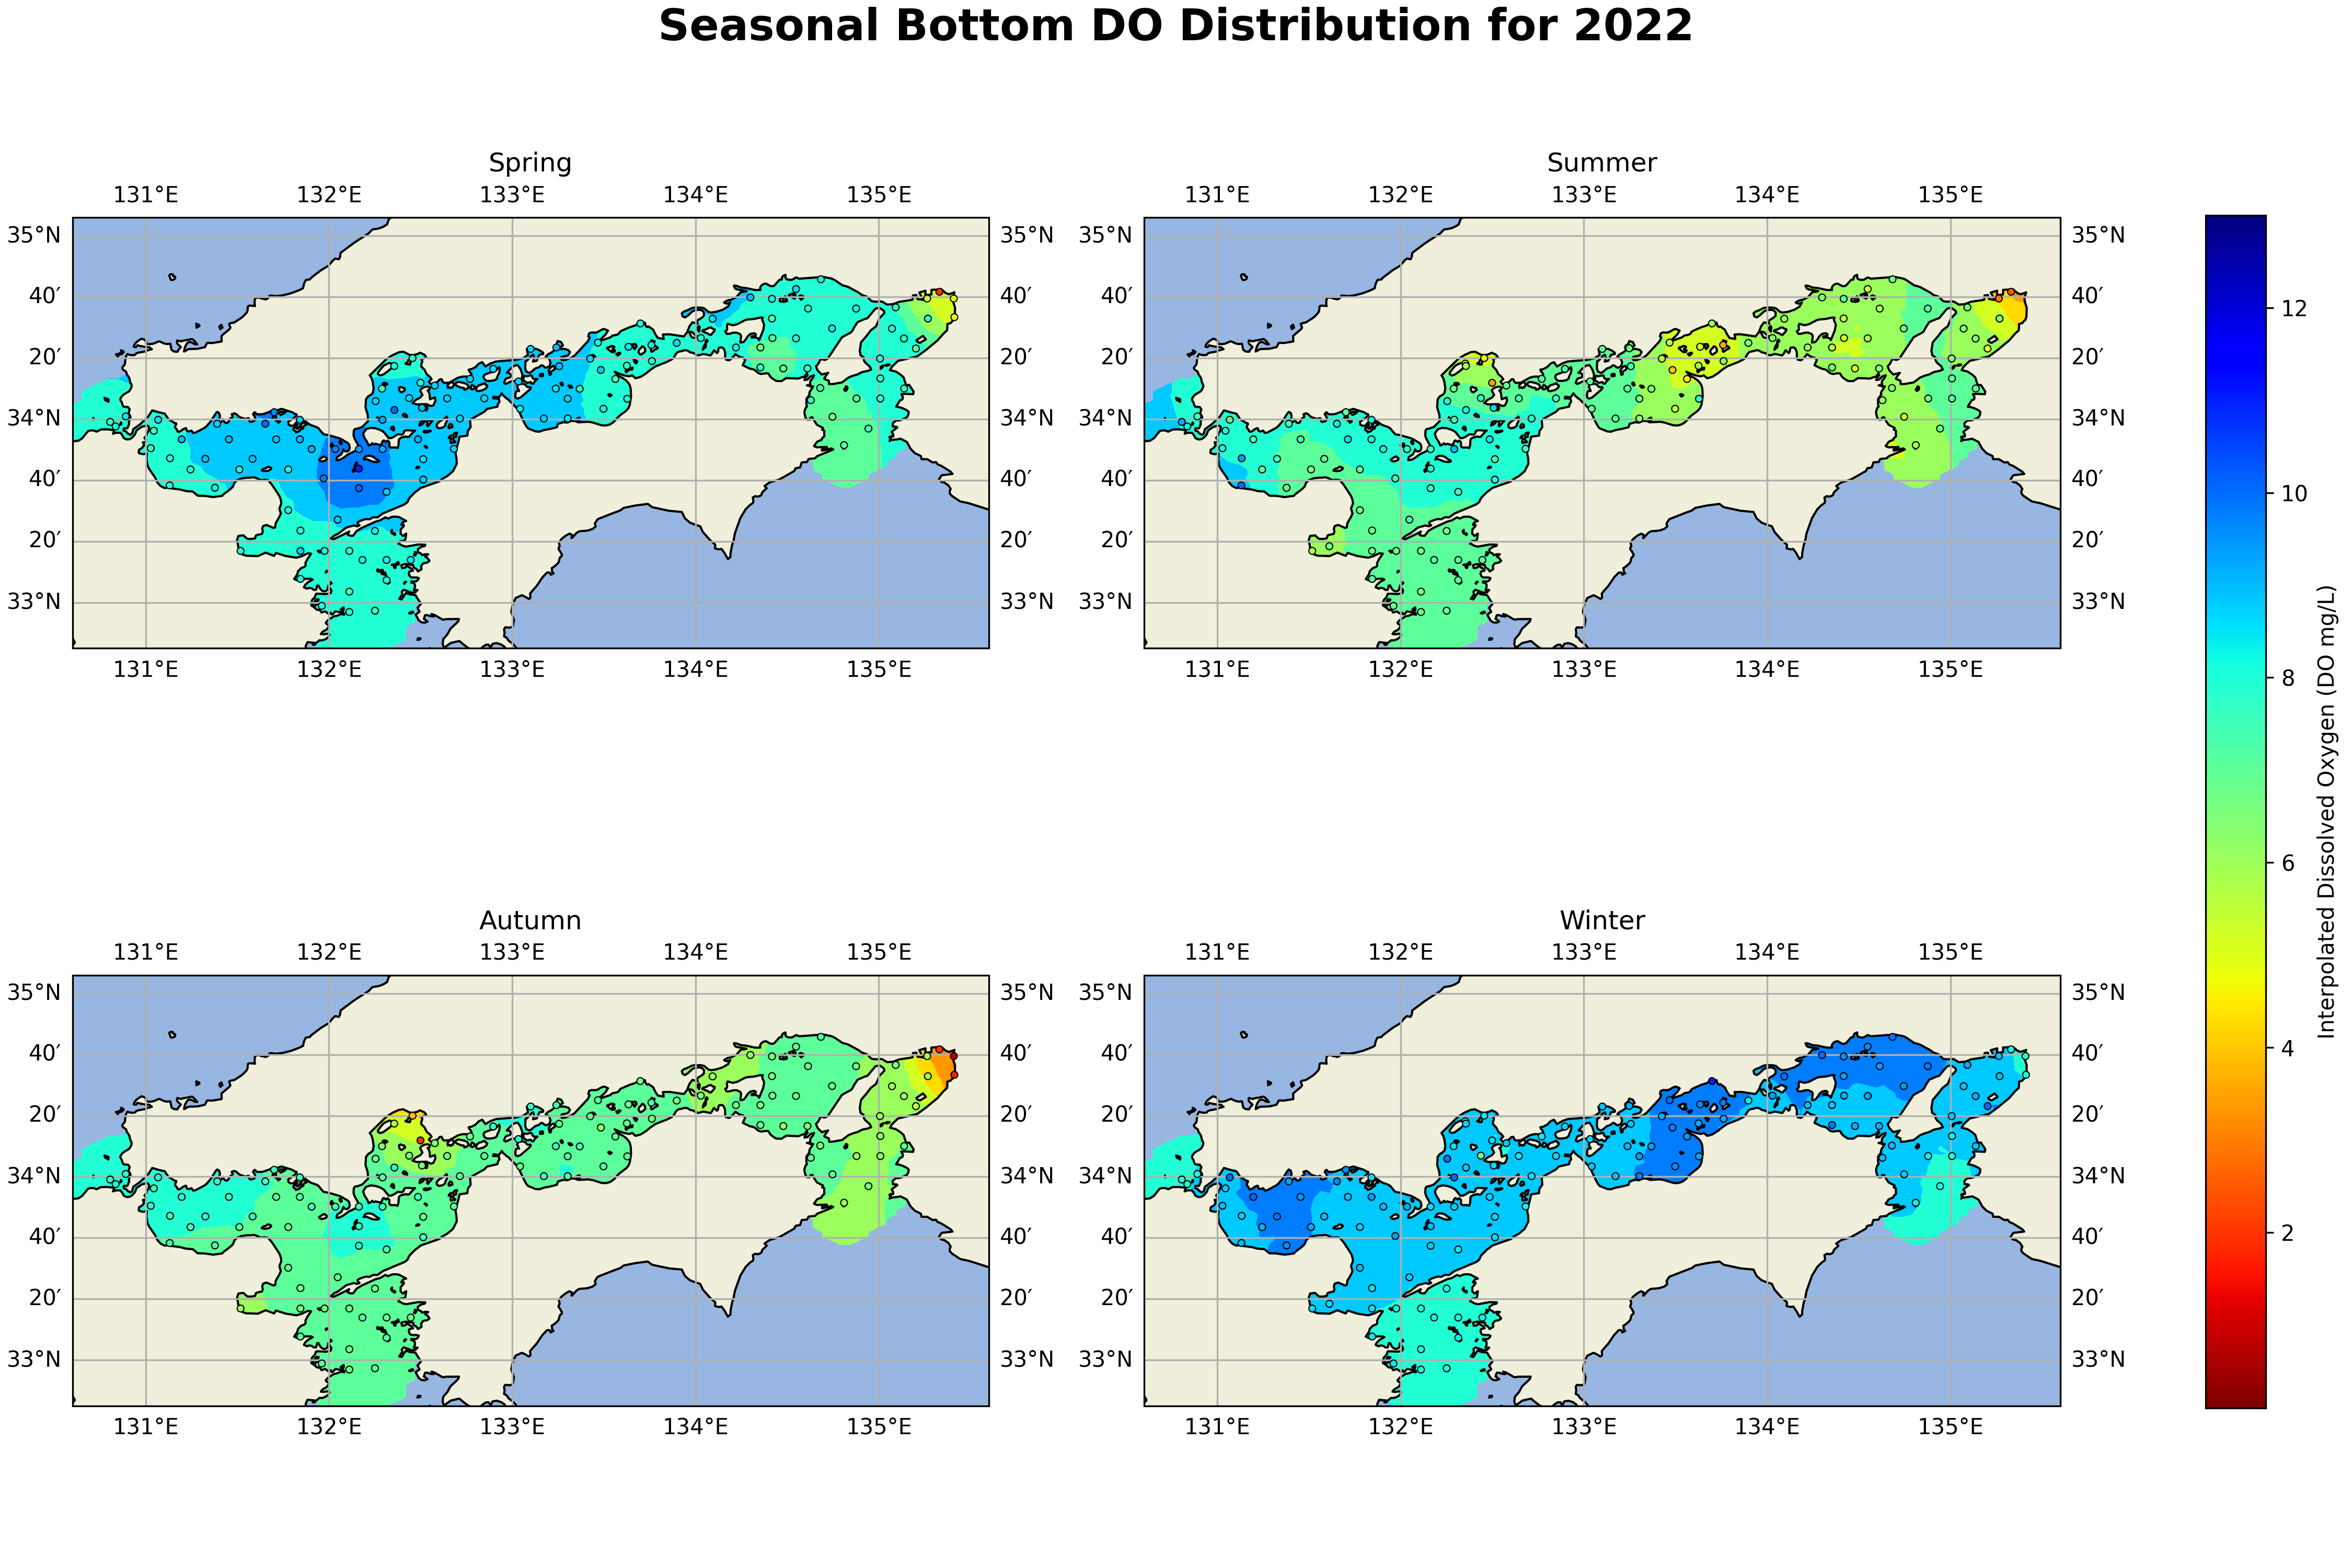

In [ ]:
def create_seasonal_maps_for_year(year, data, vmin, vmax, output_dir):
    """
    Generates and saves a 2x2 grid of seasonal SST heatmaps for a given year.
    """
    # --- Create the 2x2 subplot figure ---
    fig, axes = plt.subplots(
        2, 2, figsize=(15, 10),
        subplot_kw={'projection': ccrs.PlateCarree()},
        constrained_layout=True
    )
    fig.suptitle(f'Seasonal Bottom SST Distribution for {year}', fontsize=20, fontweight='bold')
    # Flatten the 2x2 axes array for easy iteration
    axes = axes.flatten()
    
    # Store the last contour plot to use for the single, shared colorbar
    last_contour = None
    seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
    extent = [130.6, 135.6, 32.75, 35.1]
    grid_res_x, grid_res_y = (100j, 100j)

    # --- Inner loop to create a map for each season ---
    for i, season in enumerate(seasons):
        ax = axes[i]
        ax.set_extent(extent, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.OCEAN, zorder=0)
        ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, zorder=3)
        ax.set_title(season)

        # Filter data for the specific year AND season (SST)
        year_season_data = data[
            (data['year'] == year) &
            (data['season'] == season)
        ]
        
        if len(year_season_data) > 3:
            # --- Interpolation ---
            measured_coords = np.array([year_season_data.geometry.x, year_season_data.geometry.y]).T
            measured_values = year_season_data['temp'].values
            grid_x, grid_y = np.mgrid[extent[0]:extent[1]:grid_res_x, extent[2]:extent[3]:grid_res_y]
            target_coords = np.array([grid_x.flatten(), grid_y.flatten()]).T

            # --- Apply Distance-Weighted Interpolation ---
            distances = cdist(target_coords, measured_coords)
            weights = np.exp(-((distances / D_parameter)**2))
            weights[distances > D_parameter] = 0

            # Compute the weighted averages
            sum_of_weights = np.sum(weights, axis=1)
            weighted_sum_of_values = np.sum(weights * measured_values[np.newaxis, :], axis=1)
    
            estimated_sst = np.full(target_coords.shape[0], np.nan)
            valid_indices = sum_of_weights > 1e-6
            estimated_sst[valid_indices] = weighted_sum_of_values[valid_indices] / sum_of_weights[valid_indices]

            grid_z = estimated_sst.reshape(grid_x.shape)

            # --- Plotting the heatmap ---
            contour = ax.contourf(
                grid_x, grid_y, grid_z,
                levels=np.linspace(vmin, vmax, 15),
                cmap='jet_r', vmin=vmin, vmax=vmax,
                transform=ccrs.PlateCarree(), zorder=1
            )
            last_contour = contour

            # --- FIX: Plot the original data points on top for context ---
            ax.scatter(
                year_season_data.geometry.x,
                year_season_data.geometry.y,
                c=year_season_data['temp'],        # Color points based on this column
                cmap='jet_r',
                vmin=vmin, vmax=vmax,
                edgecolor='black',
                linewidth=0.5,
                transform=ccrs.PlateCarree(),
                s=10,                     # Point size
                zorder=3                   # Draw on the very top layer
            )
        else:
            ax.text(0.5, 0.5, 'No Data', transform=ax.transAxes, ha='center', va='center', fontsize=15)
    
        # --- PRESERVE STYLE: Draw Land and Coastlines on TOP of the heatmap ---
        ax.add_feature(cfeature.LAND, edgecolor='black', zorder=1)
        #ax.add_feature(cfeature.COASTLINE, zorder=2)
        
    # --- PRESERVE STYLE: Add a single colorbar for the whole figure ---
    if last_contour:
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        mappable = cm.ScalarMappable(norm=norm, cmap='jet_r')
        cbar = fig.colorbar(mappable, ax=axes, orientation='vertical', fraction=0.03, pad=0.04)
        cbar.set_label('Interpolated Surface Temperature (SST °C)')

    # Save the composite figure for the year
    output_path = os.path.join(output_dir, f'frame_{year}.png')
    plt.savefig(output_path, dpi=300) # Removed bbox_inches='tight' for consistency
    plt.close(fig)
    print(f"Saved frame for {year} to {output_path}")

# --- Setup your parameters once ---
output_dir = '../reports/figures/seasonal_gif_frames'
os.makedirs(output_dir, exist_ok=True)
years = sorted(analysis_df['year'].unique())

# --- Call the function for a single year to test ---
test_year = 2022
create_seasonal_maps_for_year(test_year, analysis_df, vmin, vmax, output_dir)

# show the saved file
from IPython.display import Image
Image(filename=f'../reports/figures/seasonal_gif_frames/frame_{test_year}.png')

In [36]:
# --- Production Loop --- 
for year in years:
    create_seasonal_maps_for_year(year, analysis_df, vmin, vmax, output_dir)

print("\nAll seasonal maps have been generated.")

Saved frame for 1981 to ../reports/figures/seasonal_gif_frames\frame_1981.png
Saved frame for 1982 to ../reports/figures/seasonal_gif_frames\frame_1982.png
Saved frame for 1983 to ../reports/figures/seasonal_gif_frames\frame_1983.png
Saved frame for 1984 to ../reports/figures/seasonal_gif_frames\frame_1984.png
Saved frame for 1985 to ../reports/figures/seasonal_gif_frames\frame_1985.png
Saved frame for 1986 to ../reports/figures/seasonal_gif_frames\frame_1986.png
Saved frame for 1987 to ../reports/figures/seasonal_gif_frames\frame_1987.png
Saved frame for 1988 to ../reports/figures/seasonal_gif_frames\frame_1988.png
Saved frame for 1989 to ../reports/figures/seasonal_gif_frames\frame_1989.png
Saved frame for 1990 to ../reports/figures/seasonal_gif_frames\frame_1990.png
Saved frame for 1991 to ../reports/figures/seasonal_gif_frames\frame_1991.png
Saved frame for 1992 to ../reports/figures/seasonal_gif_frames\frame_1992.png
Saved frame for 1993 to ../reports/figures/seasonal_gif_frames\f

In [ ]:
# --- 5. Create the Final GIF Animation ---
print("\nStitching frames into a GIF...")
images = []
file_list = sorted(glob.glob(os.path.join(output_dir, '*.png')))

for filename in file_list:
    images.append(imageio.imread(filename))

gif_path = '../reports/figures/animations/seasonal_SST_animation.gif'
imageio.mimsave(gif_path, images, fps=1) # 1 second per year

print(f"✅ Animation saved successfully to {gif_path}")


Stitching frames into a GIF...
✅ Animation saved successfully to ../reports/figures/animations/seasonal_do_animation.gif
